# Chapter 5 — Data Exploration

COM7014 Advanced Computing Project
Muhammad Obaid Ur Rehman (STU1215887)

This notebook explores both datasets before any modelling. The purpose is not
just to produce figures, it is to establish two things the rest of the project
depends on:

1. That the training data is balanced and clean enough to train on.
2. That Dataset A and Dataset B are genuinely different from each other. If they
   were similar, the cross-dataset test in Chapter 6 would prove nothing.

Figures are saved to `results/figures/` and referenced in the report.

## 1. Setup

In [1]:
import sys
from pathlib import Path

# Allow importing from src/ when running inside notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from utils import load_config, set_seed

config = load_config(ROOT / "config.yaml")
set_seed(config["project"]["seed"])

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 200
plt.rcParams["savefig.bbox"] = "tight"

FIGDIR = ROOT / config["paths"]["figures"]
FIGDIR.mkdir(parents=True, exist_ok=True)
MANIFESTS = ROOT / config["paths"]["manifests"]

print("Project root:", ROOT)
print("Figures ->", FIGDIR)

Project root: C:\Users\obaid\OneDrive - MSFT\Desktop\Advance Computing (Dessertation)\deepfake-detection-msc
Figures -> C:\Users\obaid\OneDrive - MSFT\Desktop\Advance Computing (Dessertation)\deepfake-detection-msc\results\figures


## 2. Load the split manifests

Produced by `src/data_prep.py`. Every split is seeded and disjoint, so
re-running this notebook gives identical results.

In [2]:
def load_split(name):
    f = MANIFESTS / f"subset_{name}.csv"
    if not f.exists():
        raise FileNotFoundError(
            f"{f} not found. Run: python src/data_prep.py --step subset"
        )
    df = pd.read_csv(f)
    df["abspath"] = df["path"].apply(lambda p: ROOT / p)
    return df

train = load_split("train")
val   = load_split("val")
test  = load_split("test")
cross = load_split("crosstest")

summary = pd.DataFrame([
    {"split": n,
     "images": len(d),
     "real": int((d.label == 0).sum()),
     "fake": int((d.label == 1).sum()),
     "source": "A (StyleGAN/FFHQ)" if n != "crosstest" else "B (OpenForensics)"}
    for n, d in [("train", train), ("val", val),
                 ("test", test), ("crosstest", cross)]
])
summary

,split,images,real,fake,source
0,train,20000,10000,10000,A (StyleGAN/FFHQ)
1,val,4000,2000,2000,A (StyleGAN/FFHQ)
2,test,4000,2000,2000,A (StyleGAN/FFHQ)
3,crosstest,6000,3000,3000,B (OpenForensics)


### Class balance

Both classes are sampled equally by construction, so accuracy is a meaningful
metric here. On an imbalanced set it would not be, and we would have to lead
with F1 and PR-AUC instead.

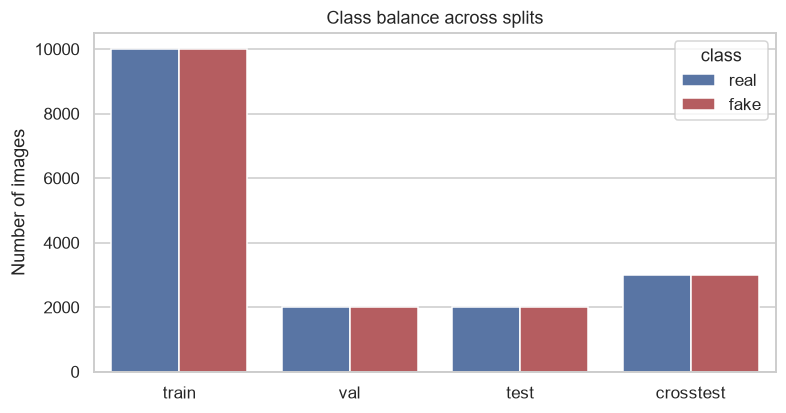

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
plot_df = summary.melt(id_vars="split", value_vars=["real", "fake"],
                       var_name="class", value_name="count")
sns.barplot(data=plot_df, x="split", y="count", hue="class", ax=ax,
            palette={"real": "#4C72B0", "fake": "#C44E52"})
ax.set_title("Class balance across splits")
ax.set_xlabel("")
ax.set_ylabel("Number of images")
plt.savefig(FIGDIR / "fig_5_01_class_balance.png")
plt.show()

## 3. Sample images

A visual check. Worth looking carefully — if the fakes are obvious to the eye,
the task is easier than the literature suggests and that needs saying in the
evaluation.

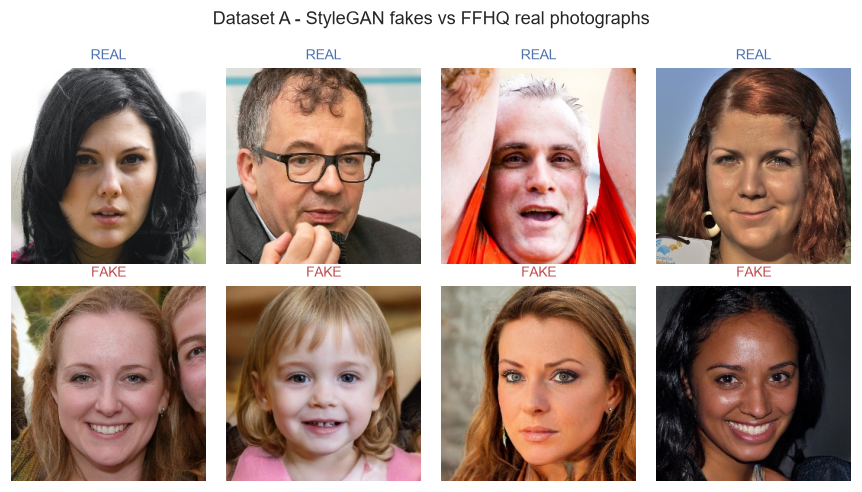

In [4]:
def show_grid(df, title, n=8, fname=None, seed=42):
    # n/2 per class, written explicitly rather than with groupby().apply()
    # because that pattern is deprecated in pandas 2.2+.
    parts = [g.sample(min(n // 2, len(g)), random_state=seed)
             for _, g in df.groupby("label")]
    sample = pd.concat(parts).reset_index(drop=True)

    cols = n // 2
    fig, axes = plt.subplots(2, cols, figsize=(2 * cols, 4.6))
    for ax in axes.flat:
        ax.axis("off")

    for label, row_axes in zip([0, 1], axes):
        subset = sample[sample.label == label].reset_index(drop=True)
        for i, ax in enumerate(row_axes):
            if i < len(subset):
                try:
                    ax.imshow(Image.open(subset.loc[i, "abspath"]).convert("RGB"))
                except Exception:
                    ax.text(0.5, 0.5, "load\nerror", ha="center",
                            va="center", fontsize=7)
                ax.set_title("REAL" if label == 0 else "FAKE", fontsize=9,
                             color="#4C72B0" if label == 0 else "#C44E52")

    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    if fname:
        plt.savefig(FIGDIR / fname)
    plt.show()


show_grid(train, "Dataset A - StyleGAN fakes vs FFHQ real photographs",
          fname="fig_5_02_samples_dataset_a.png")

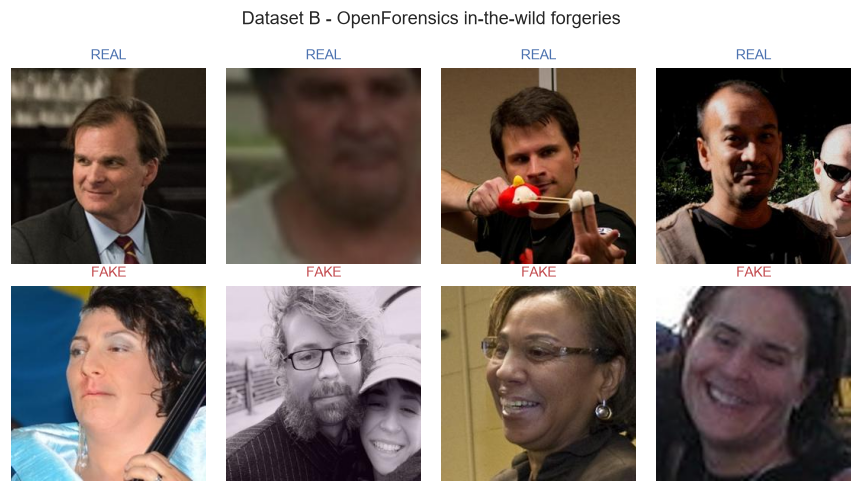

In [5]:
show_grid(cross, "Dataset B - OpenForensics in-the-wild forgeries",
          fname="fig_5_03_samples_dataset_b.png")

## 4. Image properties

Now the important part. We compare the two datasets statistically to evidence
the **domain gap** — the thing that makes the cross-dataset test in Chapter 6
worth running.

Sampling a few hundred images per dataset rather than all of them, because
opening tens of thousands of JPEGs is slow and adds nothing.

In [6]:
def image_stats(df, n=400, seed=42):
    sample = df.sample(min(n, len(df)), random_state=seed)
    rows = []
    for _, r in sample.iterrows():
        try:
            with Image.open(r["abspath"]) as im:
                im = im.convert("RGB")
                w, h = im.size
                a = np.asarray(im, dtype=np.float32) / 255.0
            rows.append({
                "label": r["label"],
                "width": w,
                "height": h,
                "mean": a.mean(),
                "std": a.std(),
                "r_mean": a[:, :, 0].mean(),
                "g_mean": a[:, :, 1].mean(),
                "b_mean": a[:, :, 2].mean(),
                # Crude sharpness proxy: variance of the vertical pixel
                # gradient. Compression and upscaling both reduce this.
                "sharpness": np.diff(a.mean(axis=2), axis=0).var(),
            })
        except Exception:
            continue
    return pd.DataFrame(rows)


stats_a = image_stats(train)
stats_b = image_stats(cross)
stats_a["dataset"] = "A (StyleGAN)"
stats_b["dataset"] = "B (OpenForensics)"
stats = pd.concat([stats_a, stats_b], ignore_index=True)

print("Dataset A resolutions:", stats_a.groupby(["width", "height"]).size().to_dict())
print("Dataset B resolutions:", stats_b.groupby(["width", "height"]).size().to_dict())
stats.groupby("dataset")[["mean", "std", "sharpness"]].agg(["mean", "std"]).round(4)

Dataset A resolutions: {(256, 256): 400}
Dataset B resolutions: {(256, 256): 400}


mean             std         sharpness        
                     mean     std    mean     std      mean     std
dataset                                                            
A (StyleGAN)       0.4398  0.1122  0.2435  0.0407    0.0027  0.0016
B (OpenForensics)  0.4042  0.1334  0.2338  0.0516    0.0013  0.0012

### 4.1 Brightness and contrast distributions

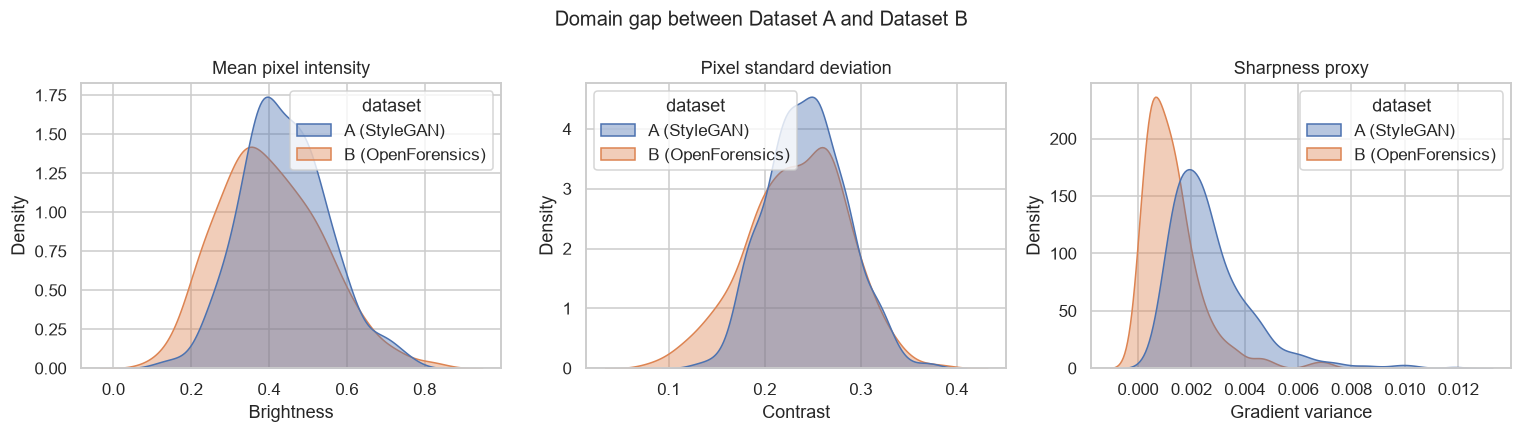

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

sns.kdeplot(data=stats, x="mean", hue="dataset", fill=True, alpha=0.4, ax=axes[0])
axes[0].set_title("Mean pixel intensity")
axes[0].set_xlabel("Brightness")

sns.kdeplot(data=stats, x="std", hue="dataset", fill=True, alpha=0.4, ax=axes[1])
axes[1].set_title("Pixel standard deviation")
axes[1].set_xlabel("Contrast")

sns.kdeplot(data=stats, x="sharpness", hue="dataset", fill=True, alpha=0.4, ax=axes[2])
axes[2].set_title("Sharpness proxy")
axes[2].set_xlabel("Gradient variance")

fig.suptitle("Domain gap between Dataset A and Dataset B", fontsize=13)
plt.tight_layout()
plt.savefig(FIGDIR / "fig_5_04_domain_gap.png")
plt.show()

> **Reading this figure.** The further apart these distributions are, the harder
> the cross-dataset transfer will be, and the more informative the result. If
> they overlapped almost completely, a good A to B score would just mean the two
> datasets were near-duplicates rather than that the model generalises.

### 4.2 Within-dataset separability

Do real and fake images differ on these simple statistics *within* Dataset A?

This matters more than it looks. If a naive statistic already separates the
classes cleanly, then a CNN scoring 97% is not necessarily learning anything
sophisticated — it might be picking up a colour or sharpness artefact of the
generator. That is exactly the kind of shortcut that collapses on Dataset B,
and it is the argument this project is making.

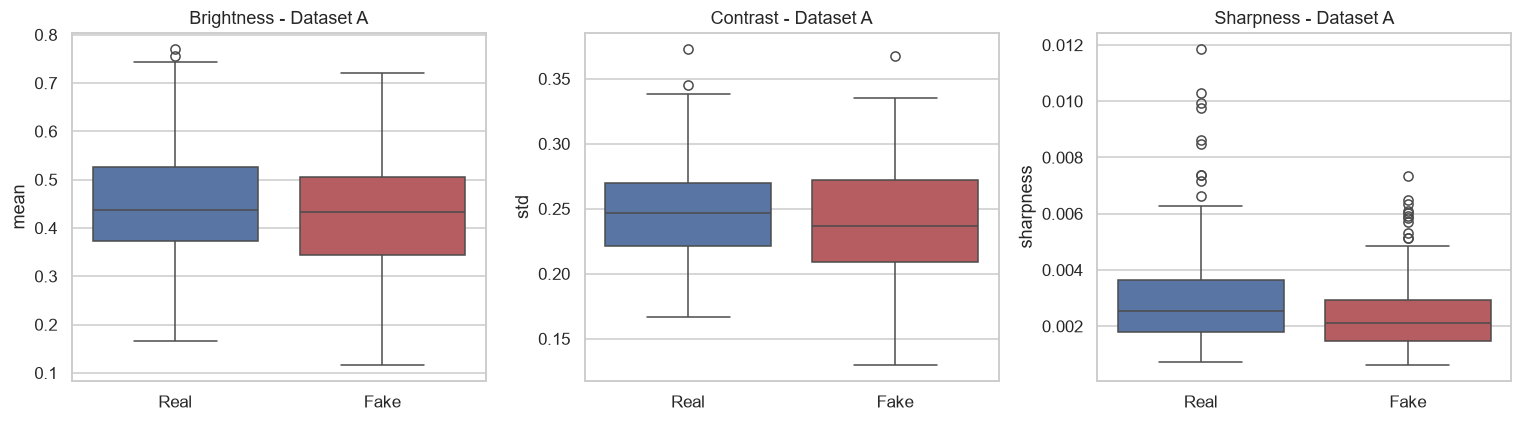

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, title in zip(axes,
                          ["mean", "std", "sharpness"],
                          ["Brightness", "Contrast", "Sharpness"]):
    sns.boxplot(data=stats_a, x="label", y=col, ax=ax, hue="label",
                palette={0: "#4C72B0", 1: "#C44E52"}, legend=False)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Real", "Fake"])
    ax.set_title(f"{title} - Dataset A")
    ax.set_xlabel("")

plt.tight_layout()
plt.savefig(FIGDIR / "fig_5_05_class_separability.png")
plt.show()

In [9]:
# Quantify separability rather than eyeballing the boxplots.
#
# Two measures, because they answer different questions:
#   p-value (Mann-Whitney U) - "is there ANY difference?"
#   AUC                      - "how BIG is it / how usable as a classifier?"
#
# At n=500 almost any difference becomes statistically significant, so the
# p-value on its own is close to meaningless here. AUC is the honest number:
# 0.50 means the feature is useless, 1.00 means it separates perfectly.
try:
    from scipy import stats as sps

    def auc_of(x, y):
        """Prob. that a random real scores above a random fake."""
        u, p = sps.mannwhitneyu(x, y, alternative="two-sided")
        return p, u / (len(x) * len(y))

    def verdict(auc):
        d = abs(auc - 0.5)
        return ("negligible" if d < 0.05 else "weak" if d < 0.10
                else "MODERATE" if d < 0.20 else "STRONG")

    feats = [("mean", "brightness"), ("std", "contrast"),
             ("sharpness", "sharpness")]

    print("WITHIN DATASET A - can one trivial statistic separate real from fake?")
    print(f"{'feature':12s} {'p':>10s} {'AUC':>7s}  effect")
    for c, lab in feats:
        p, a = auc_of(stats_a[stats_a.label == 0][c], stats_a[stats_a.label == 1][c])
        print(f"{lab:12s} {p:10.3g} {a:7.3f}  {verdict(a)}")

    print()
    print("BETWEEN DATASETS - how far apart are A and B? (the domain gap)")
    print(f"{'feature':12s} {'AUC':>7s} {'A mean':>10s} {'B mean':>10s}  gap")
    for c, lab in feats:
        p, a = auc_of(stats_a[c], stats_b[c])
        print(f"{lab:12s} {a:7.3f} {stats_a[c].mean():10.4f} "
              f"{stats_b[c].mean():10.4f}  {verdict(a)}")

    print()
    print("Read these together. If the feature that best separates real from")
    print("fake WITHIN A is also the feature where A and B differ most, then a")
    print("model leaning on that cue will be miscalibrated on B - and the")
    print("cross-dataset score in ch6 should drop. That is a testable")
    print("prediction, not just an observation.")
except ImportError:
    print("scipy not installed - skipping significance tests.")

WITHIN DATASET A - can one trivial statistic separate real from fake?
feature               p     AUC  effect
brightness        0.102   0.547  negligible
contrast         0.0685   0.553  weak
sharpness      0.000116   0.611  MODERATE

BETWEEN DATASETS - how far apart are A and B? (the domain gap)
feature          AUC     A mean     B mean  gap
brightness     0.589     0.4398     0.4042  weak
contrast       0.545     0.2435     0.2338  negligible
sharpness      0.822     0.0027     0.0013  STRONG

Read these together. If the feature that best separates real from
fake WITHIN A is also the feature where A and B differ most, then a
model leaning on that cue will be miscalibrated on B - and the
cross-dataset score in ch6 should drop. That is a testable
prediction, not just an observation.


> **Observed on this data (n=400 per dataset, seed 42):**
>
> | | brightness | contrast | sharpness |
> |---|---|---|---|
> | Real vs fake *within* A (AUC) | 0.547 | 0.553 | **0.611** |
> | Dataset A vs B (AUC) | 0.589 | 0.545 | **0.822** |
>
> Sharpness is simultaneously the strongest single real/fake cue inside
> Dataset A *and* by far the largest difference between the two datasets
> (Dataset B averages roughly half the gradient variance of Dataset A:
> 0.0013 vs 0.0027).
>
> An independent check at n=500 gave 0.538 / 0.546 / 0.631 and
> 0.596 / 0.547 / 0.813 — same conclusions. Note that the brightness and
> contrast AUCs move by ~0.01 between samples, which is the same order as
> their distance from 0.50. They are noise. Only the sharpness result is
> stable enough to build an argument on.
>
> **Prediction for Chapter 6:** a CNN trained on Dataset A will lean on
> high-frequency artefacts, and its accuracy will fall substantially on
> Dataset B. Recorded here *before* training so the test is genuine.

### 4.3 Colour channel comparison

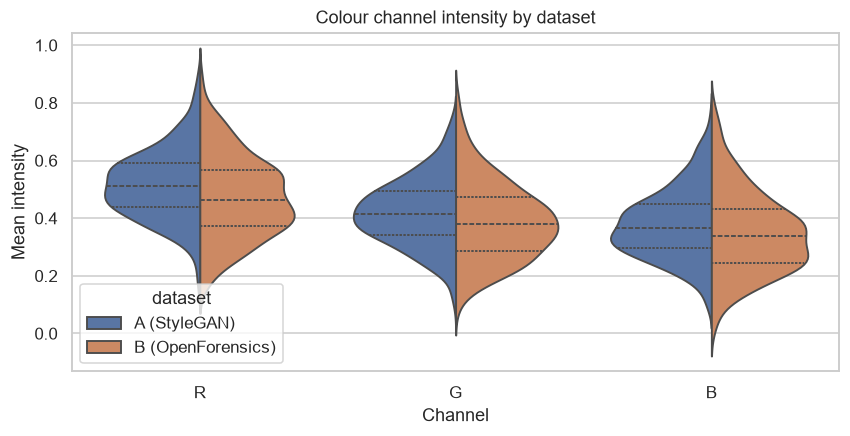

In [10]:
channel_df = stats.melt(
    id_vars=["dataset", "label"],
    value_vars=["r_mean", "g_mean", "b_mean"],
    var_name="channel",
    value_name="intensity",
)
channel_df["channel"] = channel_df["channel"].str[0].str.upper()

fig, ax = plt.subplots(figsize=(9, 4))
sns.violinplot(data=channel_df, x="channel", y="intensity", hue="dataset",
               split=True, ax=ax, inner="quart")
ax.set_title("Colour channel intensity by dataset")
ax.set_xlabel("Channel")
ax.set_ylabel("Mean intensity")
plt.savefig(FIGDIR / "fig_5_06_colour_channels.png")
plt.show()

## 5. Corruption preview

A visual preview of the perturbations used in the Chapter 6 robustness suite.
Worth including in the report so the reader can see how severe each setting
actually is — an accuracy drop at JPEG quality 10 means something different if
the image is still clearly a face than if it has been destroyed.

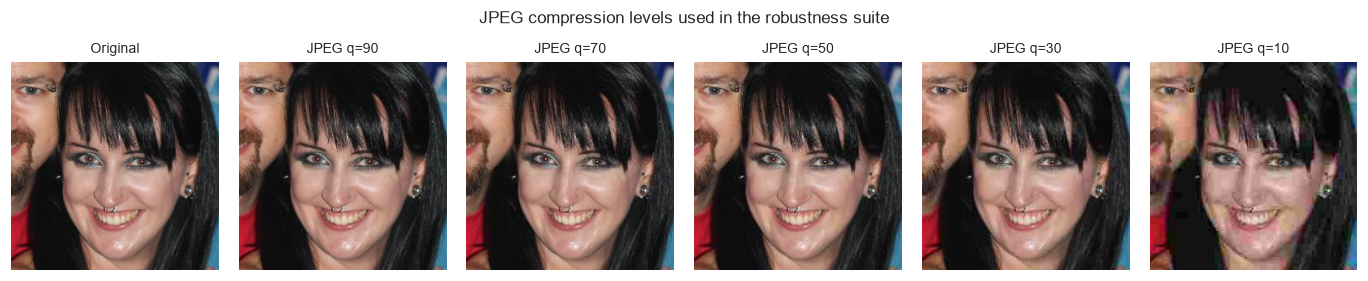

In [11]:
import io


def jpeg_compress(im, q):
    buf = io.BytesIO()
    im.save(buf, format="JPEG", quality=q)
    buf.seek(0)
    return Image.open(buf).convert("RGB")


sample_img = Image.open(
    train.sample(1, random_state=7).iloc[0]["abspath"]
).convert("RGB")

qualities = config["robustness"]["jpeg_quality"]
fig, axes = plt.subplots(1, len(qualities) + 1,
                         figsize=(2.1 * (len(qualities) + 1), 2.6))
axes[0].imshow(sample_img)
axes[0].set_title("Original", fontsize=9)
axes[0].axis("off")

for ax, q in zip(axes[1:], qualities):
    ax.imshow(jpeg_compress(sample_img, q))
    ax.set_title(f"JPEG q={q}", fontsize=9)
    ax.axis("off")

fig.suptitle("JPEG compression levels used in the robustness suite", fontsize=11)
plt.tight_layout()
plt.savefig(FIGDIR / "fig_5_07_jpeg_preview.png")
plt.show()

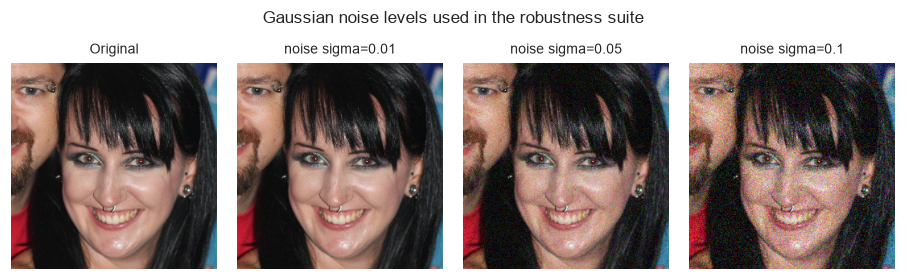

In [12]:
def add_noise(im, sigma, seed=42):
    rng = np.random.default_rng(seed)
    a = np.asarray(im, dtype=np.float32) / 255.0
    a = np.clip(a + rng.normal(0, sigma, a.shape), 0, 1)
    return Image.fromarray((a * 255).astype(np.uint8))


sigmas = config["robustness"]["gaussian_noise_sigma"]
fig, axes = plt.subplots(1, len(sigmas) + 1,
                         figsize=(2.1 * (len(sigmas) + 1), 2.6))
axes[0].imshow(sample_img)
axes[0].set_title("Original", fontsize=9)
axes[0].axis("off")

for ax, s in zip(axes[1:], sigmas):
    ax.imshow(add_noise(sample_img, s))
    ax.set_title(f"noise sigma={s}", fontsize=9)
    ax.axis("off")

fig.suptitle("Gaussian noise levels used in the robustness suite", fontsize=11)
plt.tight_layout()
plt.savefig(FIGDIR / "fig_5_08_noise_preview.png")
plt.show()

## 6. Summary

Record the observations here as you run this — these notes feed straight into
Chapter 5 of the report.

| Observation | Finding | Where it goes |
|---|---|---|
| Class balance | | §5.2 |
| Dataset A resolution / format | | §5.2 |
| Dataset B resolution / format | | §5.2 |
| Domain gap (brightness/contrast/sharpness) | | §5.3, motivates §6.5 |
| Within-dataset separability | | §5.3, revisited in §7.2 |
| Any corrupt or unreadable files | | §5.4 |

**Next:** `02_baselines.ipynb` — Logistic Regression and HOG+LBP+SVM.